In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import re

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [14]:
df=pd.read_csv(r"C:\Users\User\PycharmProjects\DineInsight\data\output.csv")

In [15]:
df

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
...,...,...
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0


In [16]:
df.columns=['text','target']

In [17]:
df.shape

(1000, 2)

In [18]:
df.head()

,text,target
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [19]:
df.tail()

,text,target
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0
999,"Then, as if I hadn't wasted enough of my life ...",0


In [20]:
df.isna().sum()

text      0
target    0
dtype: int64

In [21]:
df.dtypes

text        str
target    int64
dtype: object

In [22]:
df['target'].value_counts()

target
1    500
0    500
Name: count, dtype: int64

<Axes: xlabel='target', ylabel='count'>

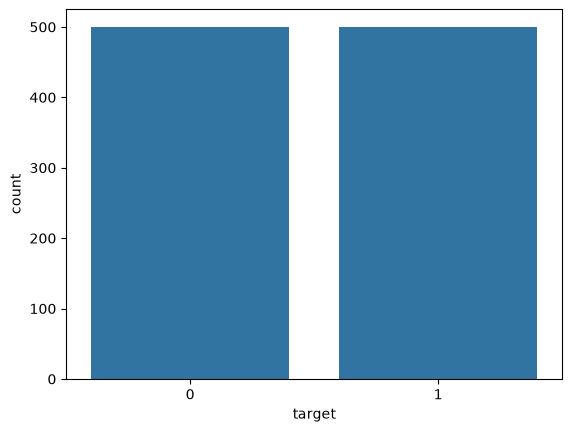

In [23]:
sns.countplot(x=df['target'])

In [24]:
tweets=df['text']

In [25]:
y=df['target']

In [26]:
#tokenization

In [27]:
from nltk.tokenize import TweetTokenizer
tk=TweetTokenizer()
tweets=tweets.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
tweets

0                             Wow ... Loved this place .
1                                    Crust is not good .
2             Not tasty and the texture was just nasty .
3      Stopped by during the late May bank holiday of...
4      The selection on the menu was great and so wer...
                             ...                        
995    I think food should have flavor and texture an...
996                            Appetite instantly gone .
997    Overall I was not impressed and would not go b...
998    The whole experience was underwhelming , and I...
999    Then , as if I hadn't wasted enough of my life...
Name: text, Length: 1000, dtype: str

In [28]:
#remove special characters
tweets=tweets.replace(['^a-zA-Z0-9'],' ',regex=True)
tweets

0                             Wow ... Loved this place .
1                                    Crust is not good .
2             Not tasty and the texture was just nasty .
3      Stopped by during the late May bank holiday of...
4      The selection on the menu was great and so wer...
                             ...                        
995    I think food should have flavor and texture an...
996                            Appetite instantly gone .
997    Overall I was not impressed and would not go b...
998    The whole experience was underwhelming , and I...
999    Then , as if I hadn't wasted enough of my life...
Name: text, Length: 1000, dtype: str

In [29]:
#remove words less than length 3

In [30]:
tweets=tweets.apply(lambda x:' '.join([w for w in tk.tokenize(x) if len(w)>=3]))

In [31]:
tweets


0                               Wow ... Loved this place
1                                         Crust not good
2               Not tasty and the texture was just nasty
3      Stopped during the late May bank holiday off R...
4      The selection the menu was great and were the ...
                             ...                        
995    think food should have flavor and texture and ...
996                              Appetite instantly gone
997         Overall was not impressed and would not back
998    The whole experience was underwhelming and thi...
999    Then hadn't wasted enough life there they pour...
Name: text, Length: 1000, dtype: str

In [32]:
#Stemming

In [33]:
from nltk.stem import SnowballStemmer
st=SnowballStemmer('english')
tweets=tweets.apply(lambda x:[st.stem(i.lower()) for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
tweets

0                                wow ... love this place
1                                         crust not good
2                not tasti and the textur was just nasti
3      stop dure the late may bank holiday off rick s...
4       the select the menu was great and were the price
                             ...                        
995    think food should have flavor and textur and b...
996                                 appetit instant gone
997            overal was not impress and would not back
998    the whole experi was underwhelm and think we'l...
999    then hadn't wast enough life there they pour s...
Name: text, Length: 1000, dtype: str

In [34]:
#Remove Stopwords

In [35]:
from nltk.corpus import stopwords
st=stopwords.words('english')
tweets=tweets.apply(lambda x:[w for w in tk.tokenize(x) if w not in st]).apply(lambda x:' '.join(x))
tweets

0                                     wow ... love place
1                                             crust good
2                                     tasti textur nasti
3      stop dure late may bank holiday rick steve rec...
4                                select menu great price
                             ...                        
995                        think food flavor textur lack
996                                 appetit instant gone
997                            overal impress would back
998    whole experi underwhelm think ninja sushi next...
999    wast enough life pour salt wound draw time too...
Name: text, Length: 1000, dtype: str

In [36]:
#vectorization

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(tweets)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5475 stored elements and shape (1000, 1568)>

In [38]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(data,y,test_size=0.30,random_state=42)

In [39]:
#ML

In [40]:
# from sklearn.ensemble import RandomForestClassifier

In [41]:
# model=RandomForestClassifier(n_estimators=10)
# model.fit(x_train,y_train)
# y_pred=model.predict(x_test)

In [42]:
# from sklearn.metrics import accuracy_score
# score=accuracy_score(y_test,y_pred)
# score

In [43]:
from sklearn.neighbors import KNeighborsClassifier
model=KNeighborsClassifier(n_neighbors=7)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [44]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred)
score

0.74

In [45]:
# sen=['price is expensive but not worth the hype']
# y_pred1=model.predict(vec.transform(sen))
# y_pred1

In [46]:
#Streamlit

In [47]:
import pickle
import  os

In [48]:
with open('models/nlp_model.pkl','wb') as file:
    pickle.dump(
        {
            'model':model,
            'tfidf':vec
        },file
    )